In [33]:
from datasets.Harmonized_Datasets import harmonize
import pandas as pd
import pylimma
import numpy as np
import decoupler as dc
import gseapy as gp
#data = harmonize()
#mf_ad = data['Moffitt'] 



In [34]:
gmt_dir = "../../data/GMT/"
hallmark_gmt = gmt_dir + "h.all.v2026.1.Hs.symbols.gmt"


In [45]:
data = harmonize()

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


DeCampos Annotated data found!
Number of Harmonized Genes: 18680


In [46]:
mf_ad = data["Moffitt"]

In [47]:
mf_ad.to_df()

,OR2T11,PAX5,BAZ2B,NDUFAB1,TSTD2,LRRC61,HMGA1,UTS2B,PLAGL1,BRAP,...,RBM17,ITGA10,CDH18,PPCDC,CHIC2,PPARGC1B,FKBP6,LIPN,PHOX2A,APCS
RNA_SampleID,,,,,,,,,,,,,,,,,,,,,
SL414065,-9.965784,5.662804,4.720880,4.499591,2.278282,0.546956,6.525302,-9.965784,0.527070,2.737903,...,5.913631,-2.826233,-9.965784,3.786701,3.623047,1.406537,-6.506353,-9.965784,-9.965784,-6.506353
SL316611,-3.816037,2.304803,4.806376,3.884696,1.091531,-2.727380,5.359697,-9.965784,1.356707,2.488258,...,5.655380,-4.608232,-9.965784,4.275082,2.821914,1.124990,-6.506353,-0.432455,-9.965784,-9.965784
SL399348,-9.965784,1.459956,4.633489,4.698274,0.971590,-2.314733,6.239188,-9.965784,1.824157,1.803640,...,4.579603,-9.965784,2.411697,1.811882,3.468714,-0.182786,-9.965784,-9.965784,-9.965784,-9.965784
SL242336,-9.965784,4.382736,4.954243,4.982811,2.131260,0.288063,4.807406,-9.965784,-1.937878,2.325099,...,6.141004,-3.625934,-2.244685,5.510044,2.874010,-0.886300,-3.816037,-9.965784,-9.965784,-9.965784
SL414057,-9.965784,0.015783,5.154656,4.111949,1.844386,-1.595097,5.724405,-2.932361,-1.117161,2.657869,...,5.354417,-5.573467,-5.011588,3.858080,2.998376,1.189666,-5.011588,-4.608232,-9.965784,-9.965784
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SL432596,-9.965784,0.288063,4.513554,4.740442,2.053459,-0.057392,6.576386,-9.965784,-1.214240,2.272322,...,5.311103,-9.965784,1.876173,5.308921,2.729226,1.632734,-5.573467,-1.430509,-9.965784,-9.965784
SL425882,-9.965784,3.681562,4.522370,5.198926,1.356707,-0.320126,8.536251,-2.244685,0.799916,2.419809,...,5.515101,-5.573467,-9.965784,4.046229,2.746528,1.664938,-9.965784,-3.816037,-9.965784,-9.965784
SL240795,-9.965784,1.709732,5.492206,4.602350,1.395611,-0.432455,5.534217,-9.965784,-0.199255,1.967538,...,5.314370,-9.965784,-0.997117,3.934611,2.443872,1.691981,-9.965784,-3.457990,-9.965784,-9.965784


In [38]:
mf_ad = mf_ad[mf_ad.obs['t11_14'].notna()]

In [39]:
mf_ad.obs

,ABT-199,ExVivo_SampleID,patientID,t11_14
RNA_SampleID,,,,
SL316611,96.238950,Pt227,GDH08065638,0.0
SL399348,65.236880,Pt382,GDH087884bf,0.0
SL242336,81.704820,Pt166,GDH0bd4be69,1.0
SL399327,90.113614,Pt387,GDH15c6174b,0.0
SL405631,82.246965,Pt401,GDH178132b2,0.0
...,...,...,...,...
SL405724,95.078404,Pt392,GDHdec9c5ce,0.0
SL375786,82.644168,Pt297,GDHe45d3d55,1.0
SL240795,88.815766,Pt143,GDHf5b6b0bc,0.0


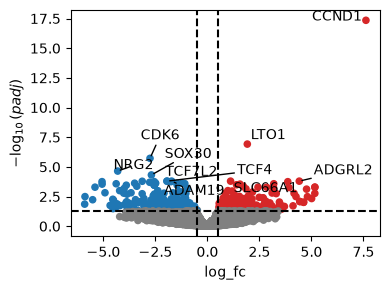

In [40]:
import matplotlib.pyplot as plt
expr = mf_ad.to_df()

design = np.column_stack([np.ones( len(mf_ad.obs['t11_14']) ), np.array(mf_ad.obs['t11_14']) ])

fit = pylimma.lm_fit(expr.transpose(), design)
fit = pylimma.contrasts_fit(fit, contrasts=np.array([[0], [1]]))
fit = pylimma.e_bayes(fit)
results_df = pylimma.top_table(fit, coef=0, number=np.inf)
#results_df = pylimma.top_table(fit, coef=1, key="fit",number=np.inf,sort_by="p")
results_df['padj'] = results_df["adj_p_value"]

dc.pl.volcano(data=results_df, x="log_fc", y="padj", top=10)
plt.show()


In [41]:
expr

,OR2T11,PAX5,BAZ2B,NDUFAB1,TSTD2,LRRC61,HMGA1,UTS2B,PLAGL1,BRAP,...,RBM17,ITGA10,CDH18,PPCDC,CHIC2,PPARGC1B,FKBP6,LIPN,PHOX2A,APCS
RNA_SampleID,,,,,,,,,,,,,,,,,,,,,
SL316611,-3.816037,2.304803,4.806376,3.884696,1.091531,-2.727380,5.359697,-9.965784,1.356707,2.488258,...,5.655380,-4.608232,-9.965784,4.275082,2.821914,1.124990,-6.506353,-0.432455,-9.965784,-9.965784
SL399348,-9.965784,1.459956,4.633489,4.698274,0.971590,-2.314733,6.239188,-9.965784,1.824157,1.803640,...,4.579603,-9.965784,2.411697,1.811882,3.468714,-0.182786,-9.965784,-9.965784,-9.965784,-9.965784
SL242336,-9.965784,4.382736,4.954243,4.982811,2.131260,0.288063,4.807406,-9.965784,-1.937878,2.325099,...,6.141004,-3.625934,-2.244685,5.510044,2.874010,-0.886300,-3.816037,-9.965784,-9.965784,-9.965784
SL399327,-9.965784,-1.732165,4.444336,4.134303,1.669480,-1.883635,5.849274,-9.965784,-2.244685,1.683023,...,4.475150,-5.573467,-1.181149,3.734547,2.795144,-0.320126,-9.965784,-5.573467,-9.965784,-9.965784
SL405631,-9.965784,0.964214,5.675280,5.368105,1.546462,-1.685014,5.716744,-9.965784,1.531569,3.072277,...,6.518236,-6.506353,-9.965784,3.746420,4.629415,-0.413115,-4.608232,-2.547932,-9.965784,-9.965784
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SL405724,-9.965784,-0.997117,5.613856,4.558941,2.014712,-1.510457,6.125382,-9.965784,-2.052895,2.049979,...,5.014400,-6.506353,-1.937878,3.273665,2.625504,-0.375197,-9.965784,-3.046921,-9.965784,-9.965784
SL375786,-9.965784,1.718526,4.786126,3.952427,0.856787,-1.354759,3.642817,-9.965784,-2.727380,2.254292,...,5.183129,-5.011588,-3.816037,2.613767,3.014534,-2.547932,-9.965784,-5.011588,-9.965784,-9.965784
SL240795,-9.965784,1.709732,5.492206,4.602350,1.395611,-0.432455,5.534217,-9.965784,-0.199255,1.967538,...,5.314370,-9.965784,-0.997117,3.934611,2.443872,1.691981,-9.965784,-3.457990,-9.965784,-9.965784


In [42]:
results_df = results_df.sort_values(by="t")
pre_res = gp.prerank(rnk=results_df, gene_sets=[hallmark_gmt], threads=8, min_size=5, max_size=1000, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")
pre_res.res2d["Term"] = (
    pre_res.res2d["Term"]
    .str.replace("h.all.v2026.1.Hs.symbols.gmt__HALLMARK_", "", regex=False)
)


2026-09-14 18:31:29,948 [WARNING] Duplicated values found in preranked stats:
sample	ratio
log_fc         5.35%
ave_expr       6.24%
t              4.56%
p_value        4.72%
adj_p_value   63.01%
b              5.70%
padj          63.01%
The order of those genes will be arbitrary, which may produce unexpected results.


In [43]:
pre_res.res2d = pre_res.res2d.drop_duplicates('Term')

<Axes: xlabel='NES'>

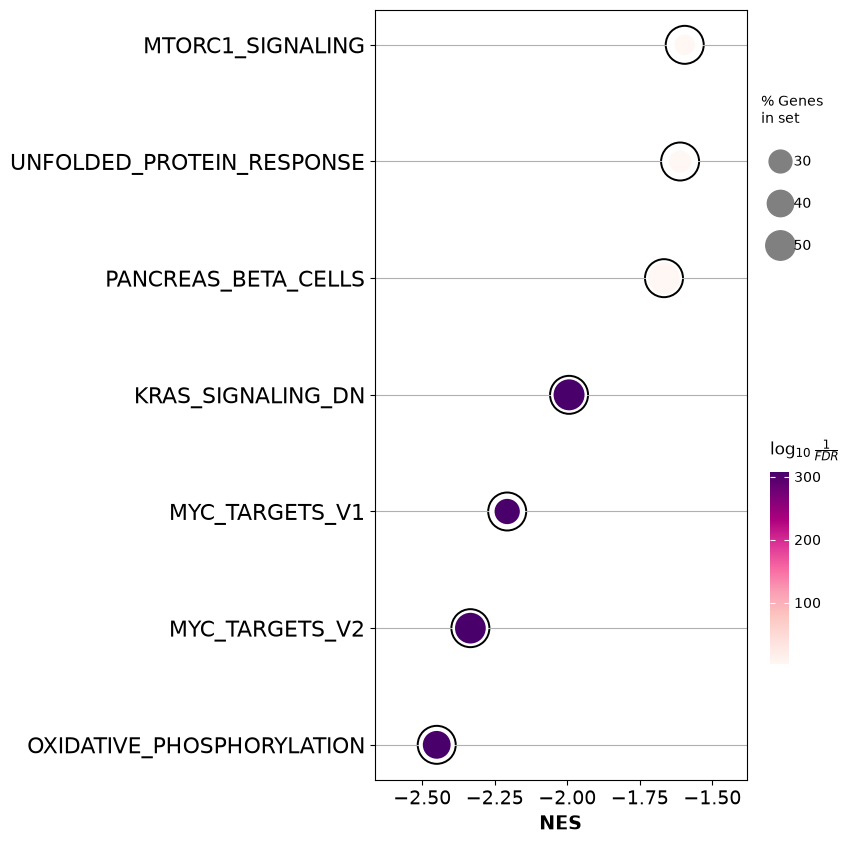

In [44]:
gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="RdPu" ,size=5,figsize=(6, 10),cutoff=0.05,show_ring=True)
